# Rule examples

## Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [
    str(ROOT / "result_summary"),
    str(ROOT / "result_summary" / "complex_rules" / "scripts"),
    str(ROOT / "result_summary" / "differential_rules" / "scripts"),
]

import final_figures_vis as fv
import rule_examples_helper as ex
import rule_trends_helper as rt
import rules_per_fov_helper as rf
import vis_helper as vh

In [2]:
NETWORK = False
WIDTH = fv.PANEL_INCHES * (5 if NETWORK else 4)
DOT = 6
FONT_SIZE = 20
N_TOP = 10
ONLY_400 = True
METRICS = ["Kind", "Support", "Confidence", "Lift", "Leverage", "Conviction", "Individual_FDR"]

## Data

In [3]:
df_cells, df_fovs, rules, has_rule = rt.load()
results = rt.all_results(df_fovs, has_rule)
all_rules = rf.with_cells(rf.load(df_fovs["FOV"]))
passed = rf.passed(all_rules)
cell_colors = vh.set_cell_colors(df_cells)
cell_counts = pd.crosstab(df_cells["fov"], df_cells["cell type"].astype(str))

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv
Loaded 15660 rules.
Kept 6978 rules at FDR <= 0.05.
Kept 6946 rules naming no Unidentified.
Kept 6946 rules (max_items=2, kind=None).
Read results_CN_pairwise.csv


## Picking FOVs

In [4]:
def pick_fov(has, rule, fovs, found):
    """Of `fovs`, the one where `has` (1 has the rule, 0 testable without it) is `found`
    and the rarer cell type of `rule` has the most cells; None when there is none."""
    fovs = has[fovs].index[has[fovs].eq(found)]
    return cell_counts.loc[fovs, list(rule)].min(axis=1).idxmax() if len(fovs) else None


def metrics(name, fov, rule):
    """`name`, `fov` and the mined METRICS of `rule` (centre, neighbour) there, of every kind and
    significance; or that it was not mined there."""
    center, neighbor = rule
    found = all_rules[all_rules["FOV"].eq(fov) & all_rules["center"].eq(center)
                      & all_rules["neighbor"].eq(neighbor)]
    return f"{name}  ·  {fov}\n" + (found[METRICS].round(3).to_string(index=False) if len(found)
                                    else "not mined in this FOV")


def rule_examples(organ, trend):
    """For each changing rule of the organ by `trend`, as in the rule trends: the FOV with the rule
    from the group where it is most common, and the FOV without it from the group where it is least
    common, each picked by `pick_fov`, scored by `ex.rule_scores`, drawn by `fv.plot_rule_examples` under
    its `metrics`; only 400 um FOVs with ONLY_400; a table of the picks."""
    fovs = df_fovs[df_fovs["Organ"].eq(organ)]
    if ONLY_400:
        fovs = fovs[fovs["Size [um]"].eq(400)]
    groups = fovs.set_index("FOV")[trend]
    picks, examples = [], {}
    for at, by, kind, result, chosen in rt.picked(results, "FOV", rt.changed):
        if (at, by) != (organ, trend):
            continue
        share = result["found"] / result["tested"]
        for name in chosen:
            rule = tuple(name.split(" -> "))
            for found, group in ((1, share.loc[name].idxmax()), (0, share.loc[name].idxmin())):
                fov = pick_fov(has_rule[kind].loc[name], rule, groups.index[groups.eq(group)], found)
                picks.append({"kind": kind, "rule": name, "group": group, "has rule": bool(found), "FOV": fov,
                              "rarer cell type's cells": cell_counts.loc[fov, list(rule)].min() if fov else None})
                if fov:
                    score = ex.rule_scores(df_cells[df_cells["fov"].eq(fov)], rule)
                    examples[f"{kind}_{'_to_'.join(rule)}_{'with' if found else 'without'}"] = (fov, rule, score)
    key = fv.key_cells(df_cells, [fov for fov, *_ in examples.values()], passed, N_TOP)
    fv.plot_rule_examples(df_cells, examples, passed, cell_colors, key, width=WIDTH, font_size=FONT_SIZE,
                          network=NETWORK, dot=DOT,
                          notes={name: metrics(name, fov, rule) for name, (fov, rule, _) in examples.items()},
                          save=f"rule_examples_FOV/{organ}_{trend.replace(' ', '_')}")
    return pd.DataFrame(picks)

## Changing rules · per FOV

### Colon · Pathological score

attracts_CD4T_to_Plasma_with  ·  Control_Colon_04_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.045        0.71 1.312     0.011       1.582           0.011
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_CD4T_to_Plasma_with.pdf


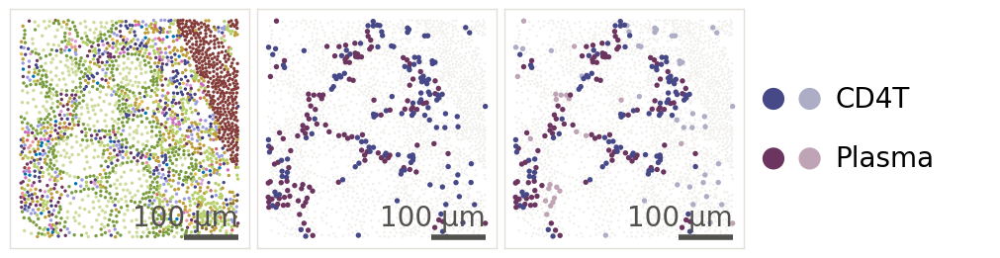

attracts_CD4T_to_Plasma_without  ·  GVHD_53_FOV_4
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_CD4T_to_Plasma_without.pdf


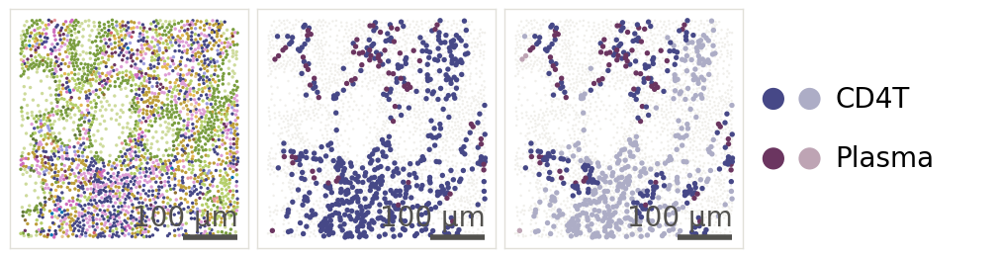

attracts_Fibroblast_to_Plasma_with  ·  Control_Colon_02_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.134       0.865 1.218     0.024       2.148           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_Fibroblast_to_Plasma_with.pdf


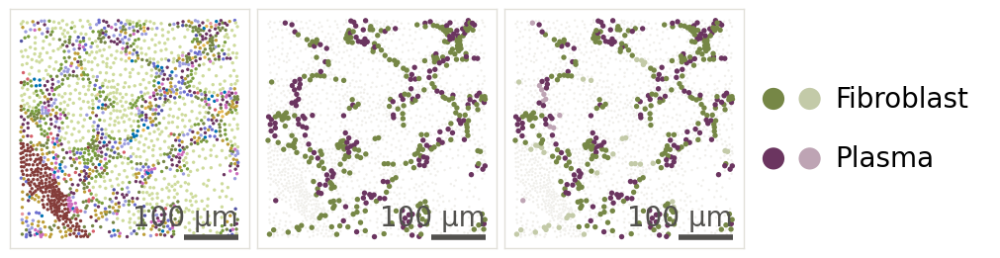

attracts_Fibroblast_to_Plasma_without  ·  GVHD_01_FOV_6_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_Fibroblast_to_Plasma_without.pdf


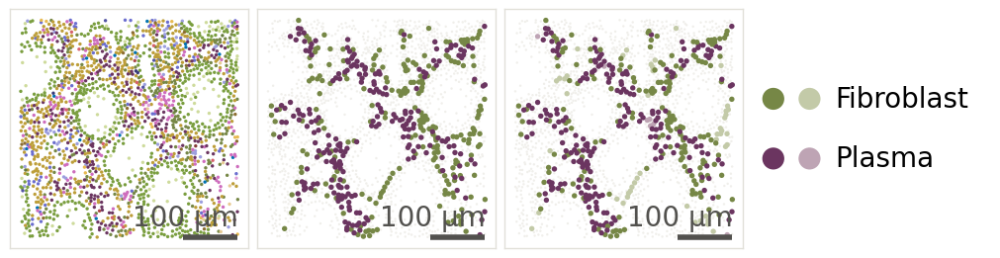

attracts_CD8T_to_Plasma_with  ·  Control_Colon_02_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.101       0.883 1.232     0.019       2.426           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_CD8T_to_Plasma_with.pdf


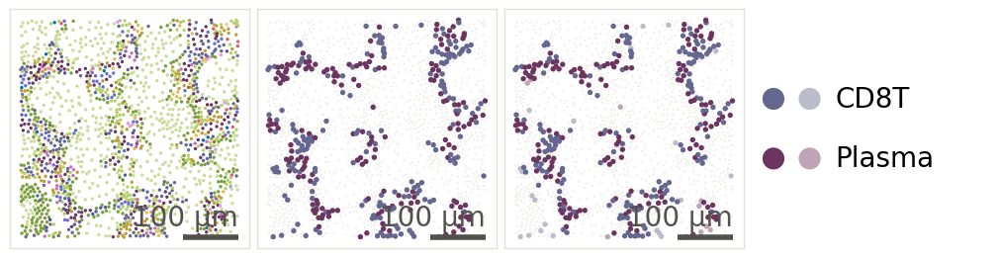

attracts_CD8T_to_Plasma_without  ·  GVHD_53_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.011       0.537 1.389     0.003       1.325             1.0
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_CD8T_to_Plasma_without.pdf


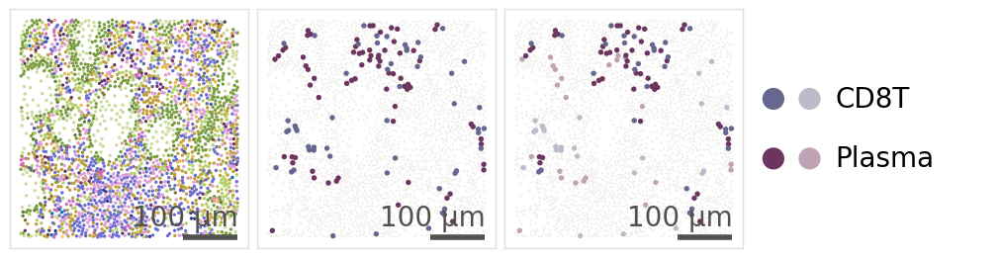

attracts_Macrophage_to_Plasma_with  ·  Control_Colon_01_FOV_1
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.126       0.897 1.205     0.021       2.488           0.004
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_Macrophage_to_Plasma_with.pdf


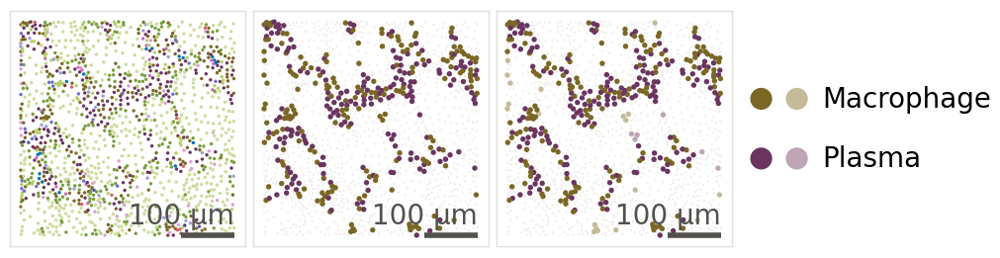

attracts_Macrophage_to_Plasma_without  ·  GVHD_42_FOV_2
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_Macrophage_to_Plasma_without.pdf


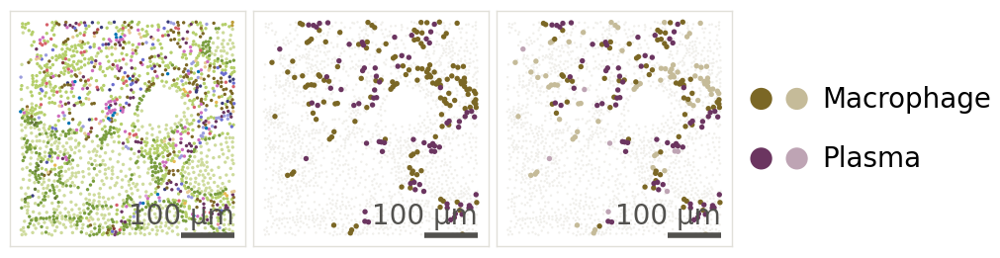

attracts_Macrophage_to_CD4T_with  ·  Control_Colon_04_FOV_1
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts      0.1       0.734 1.254      0.02       1.561           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_Macrophage_to_CD4T_with.pdf


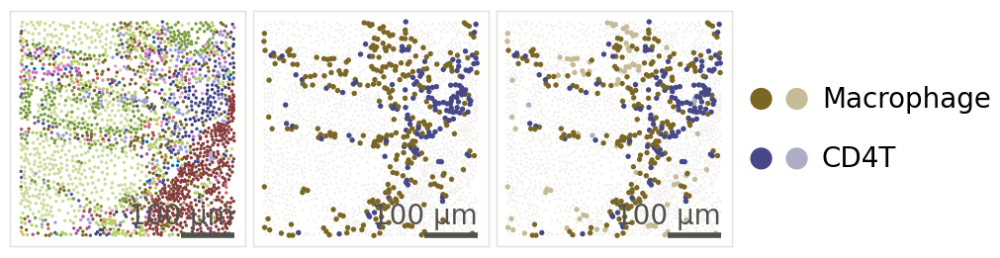

attracts_Macrophage_to_CD4T_without  ·  GVHD_48_FOV_4
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_score\attracts_Macrophage_to_CD4T_without.pdf


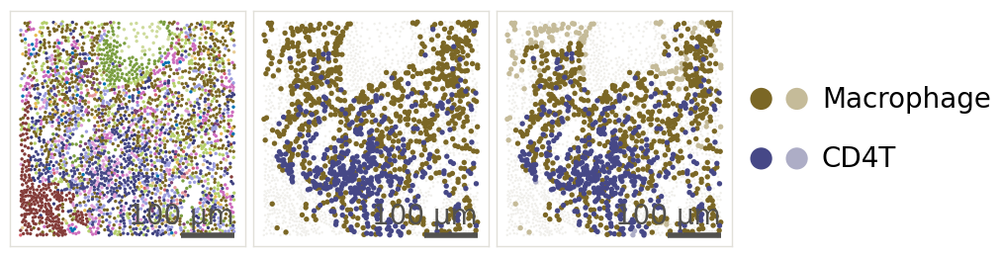

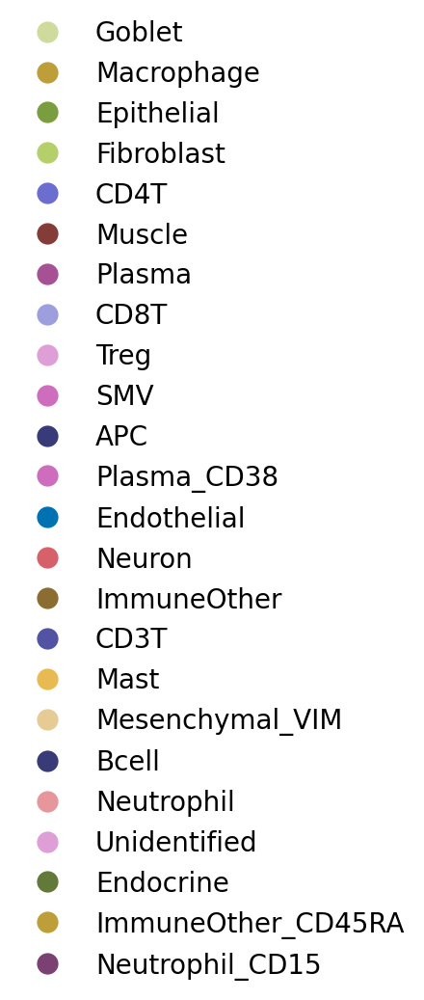

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,CD4T -> Plasma,Control,True,Control_Colon_04_FOV_4,122
1,attracts,CD4T -> Plasma,Mild,False,GVHD_53_FOV_4,72
2,attracts,Fibroblast -> Plasma,Control,True,Control_Colon_02_FOV_2,166
3,attracts,Fibroblast -> Plasma,Severe,False,GVHD_01_FOV_6_R,228
4,attracts,CD8T -> Plasma,Control,True,Control_Colon_02_FOV_3,168
5,attracts,CD8T -> Plasma,Mild,False,GVHD_53_FOV_4,54
6,attracts,Macrophage -> Plasma,Control,True,Control_Colon_01_FOV_1,181
7,attracts,Macrophage -> Plasma,Mild,False,GVHD_42_FOV_2,77
8,attracts,Macrophage -> CD4T,Control,True,Control_Colon_04_FOV_1,138
9,attracts,Macrophage -> CD4T,Severe,False,GVHD_48_FOV_4,402


In [5]:
rule_examples("Colon", "Pathological score")

### Colon · Clinical score

attracts_CD4T_to_Plasma_with  ·  Control_Colon_04_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.045        0.71 1.312     0.011       1.582           0.011
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_CD4T_to_Plasma_with.pdf


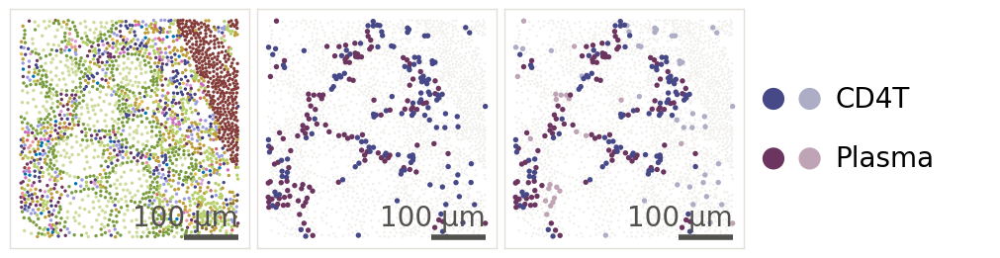

attracts_CD4T_to_Plasma_without  ·  GVHD_53_FOV_4
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_CD4T_to_Plasma_without.pdf


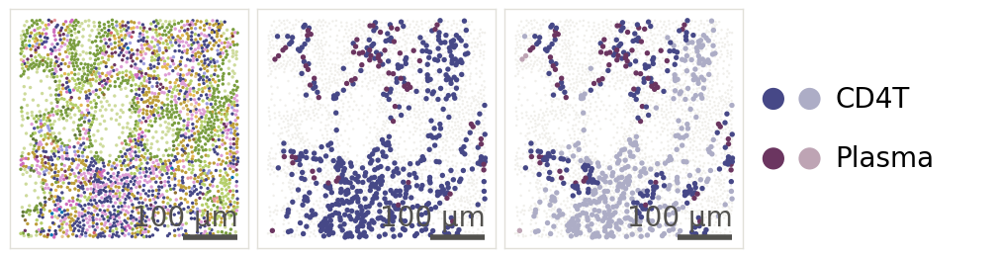

attracts_Macrophage_to_Plasma_with  ·  Control_Colon_01_FOV_1
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.126       0.897 1.205     0.021       2.488           0.004
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_Macrophage_to_Plasma_with.pdf


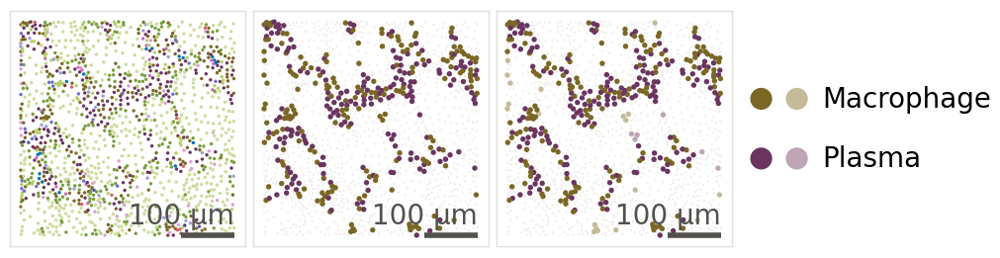

attracts_Macrophage_to_Plasma_without  ·  GVHD_53_FOV_4
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_Macrophage_to_Plasma_without.pdf


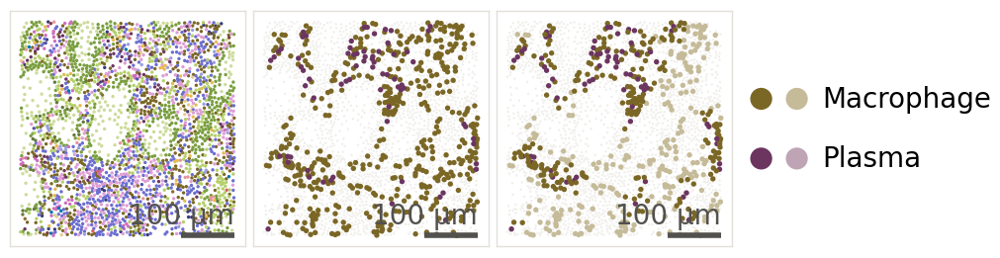

attracts_Fibroblast_to_Plasma_with  ·  Control_Colon_02_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.134       0.865 1.218     0.024       2.148           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_Fibroblast_to_Plasma_with.pdf


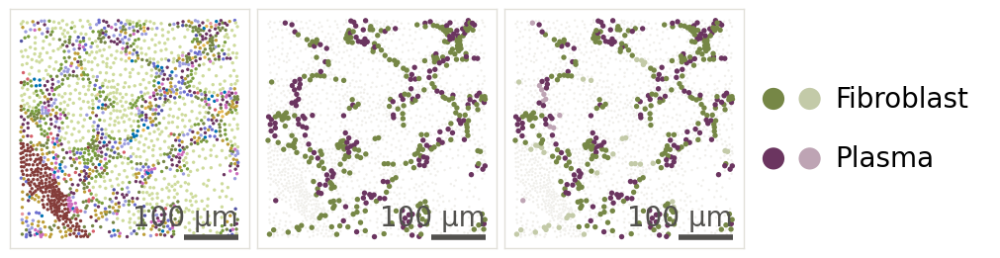

attracts_Fibroblast_to_Plasma_without  ·  GVHD_53_FOV_4
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_Fibroblast_to_Plasma_without.pdf


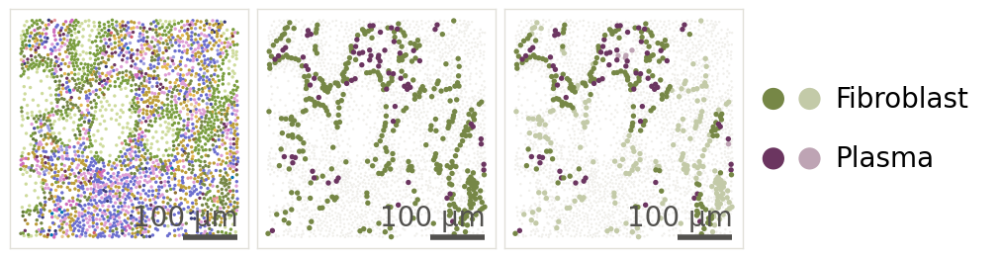

attracts_CD8T_to_Plasma_with  ·  Control_Colon_02_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.101       0.883 1.232     0.019       2.426           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_CD8T_to_Plasma_with.pdf


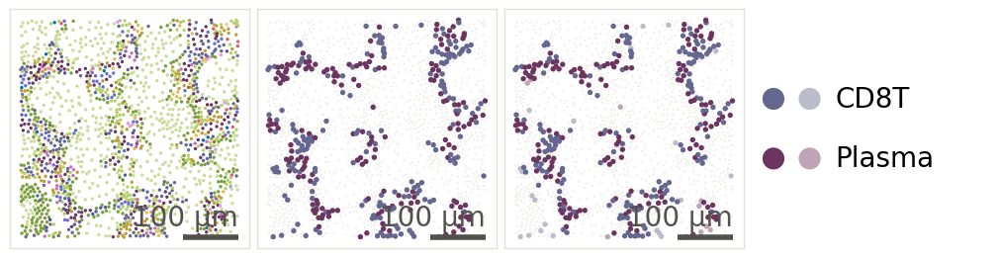

attracts_CD8T_to_Plasma_without  ·  GVHD_53_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.011       0.537 1.389     0.003       1.325             1.0
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_CD8T_to_Plasma_without.pdf


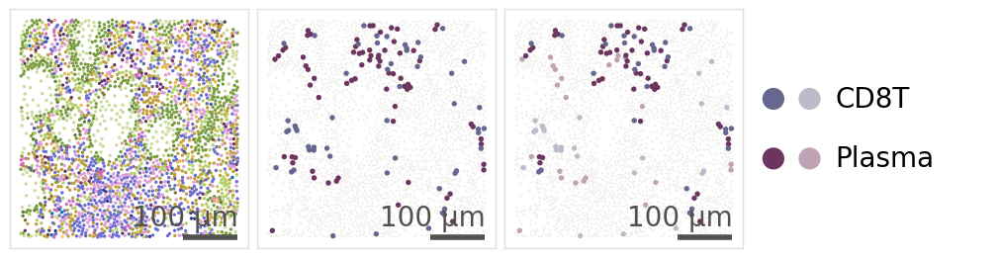

attracts_Plasma_to_CD4T_with  ·  Control_Colon_04_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.048       0.811 1.236     0.009       1.821           0.008
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_Plasma_to_CD4T_with.pdf


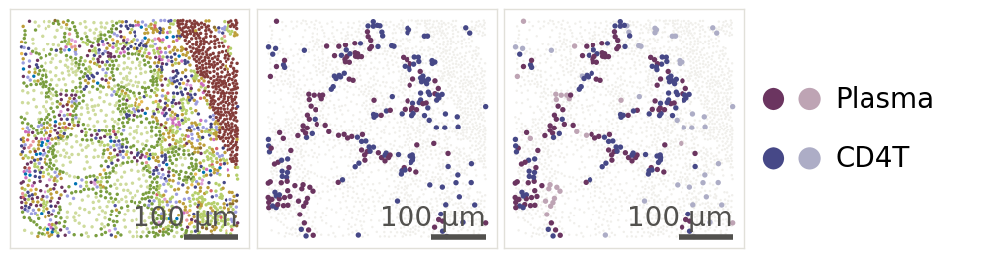

attracts_Plasma_to_CD4T_without  ·  GVHD_53_FOV_4
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\attracts_Plasma_to_CD4T_without.pdf


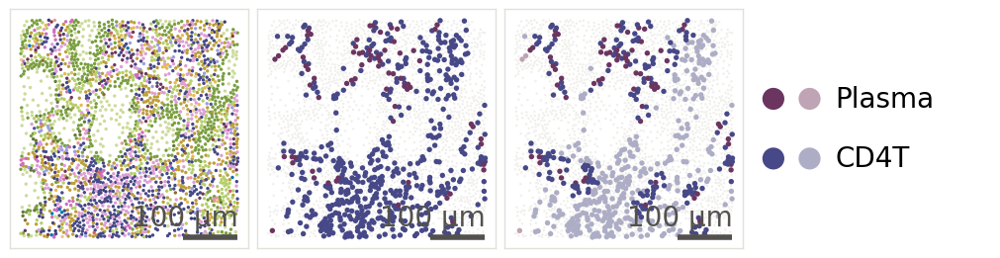

avoids_Goblet_to_Mast_with  ·  Control_Colon_03_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.055       0.281 0.564    -0.042       0.698           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\avoids_Goblet_to_Mast_with.pdf


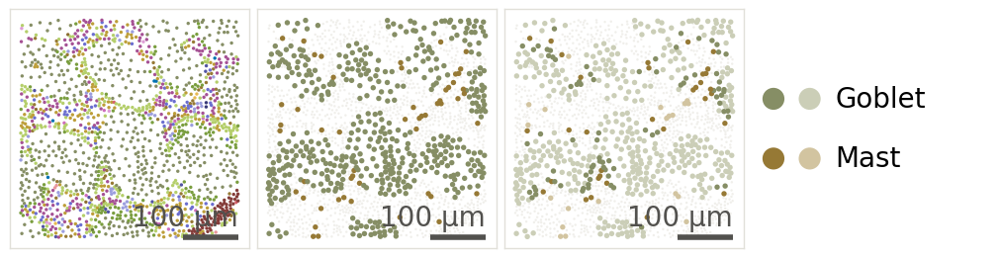

avoids_Goblet_to_Mast_without  ·  GVHD_01_FOV_2_R
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.001       0.015 0.055    -0.017        0.74           0.267
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\avoids_Goblet_to_Mast_without.pdf


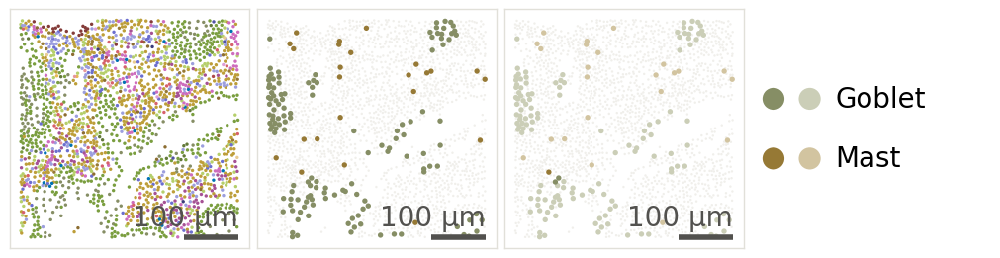

avoids_Goblet_to_Endothelial_with  ·  Control_Colon_02_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.049       0.203 0.523    -0.045       0.767           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\avoids_Goblet_to_Endothelial_with.pdf


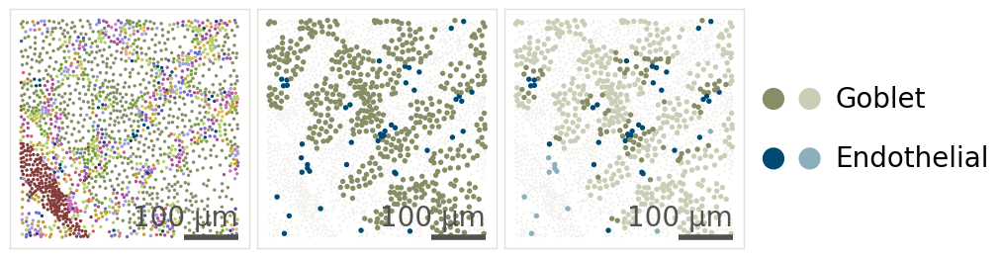

avoids_Goblet_to_Endothelial_without  ·  GVHD_21_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.004       0.045 0.185    -0.017       0.795           0.085
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Clinical_score\avoids_Goblet_to_Endothelial_without.pdf


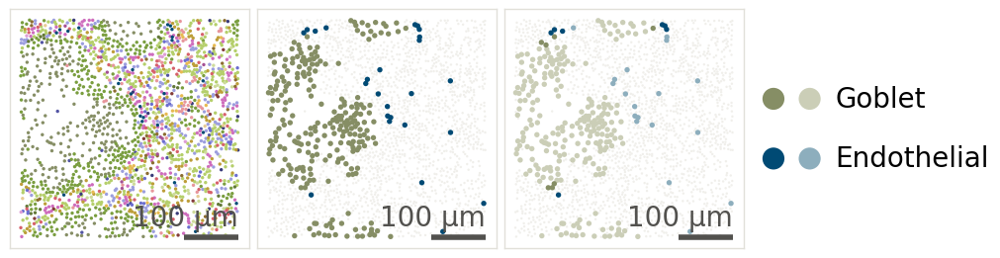

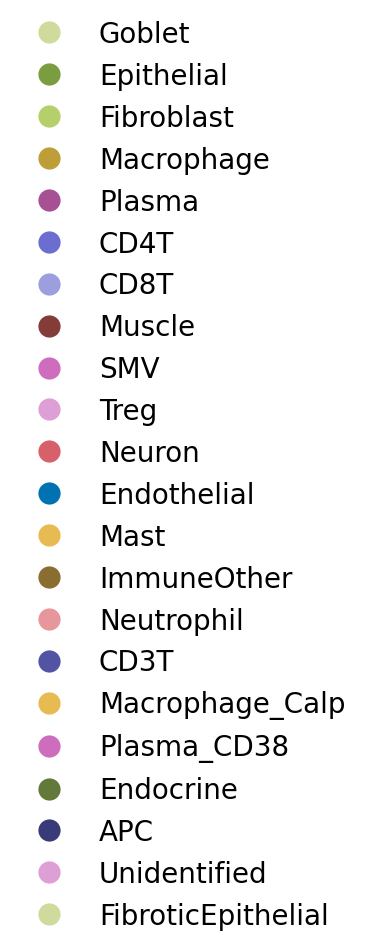

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,CD4T -> Plasma,Control,True,Control_Colon_04_FOV_4,122
1,attracts,CD4T -> Plasma,Mild,False,GVHD_53_FOV_4,72
2,attracts,Macrophage -> Plasma,Control,True,Control_Colon_01_FOV_1,181
3,attracts,Macrophage -> Plasma,Mild,False,GVHD_53_FOV_4,72
4,attracts,Fibroblast -> Plasma,Control,True,Control_Colon_02_FOV_2,166
5,attracts,Fibroblast -> Plasma,Mild,False,GVHD_53_FOV_4,72
6,attracts,CD8T -> Plasma,Control,True,Control_Colon_02_FOV_3,168
7,attracts,CD8T -> Plasma,Mild,False,GVHD_53_FOV_4,54
8,attracts,Plasma -> CD4T,Control,True,Control_Colon_04_FOV_4,122
9,attracts,Plasma -> CD4T,Mild,False,GVHD_53_FOV_4,72


In [6]:
rule_examples("Colon", "Clinical score")

### Colon · Pathological stage

avoids_Fibroblast_to_Goblet_with  ·  GVHD_21_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.063       0.324 0.529    -0.056       0.574           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_stage\avoids_Fibroblast_to_Goblet_with.pdf


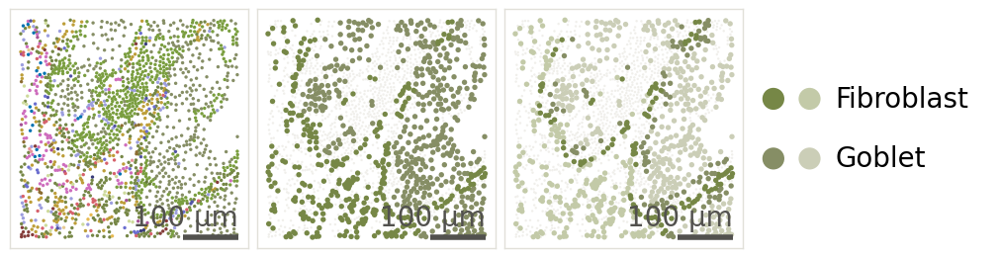

avoids_Fibroblast_to_Goblet_without  ·  GVHD_50_FOV_1
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_stage\avoids_Fibroblast_to_Goblet_without.pdf


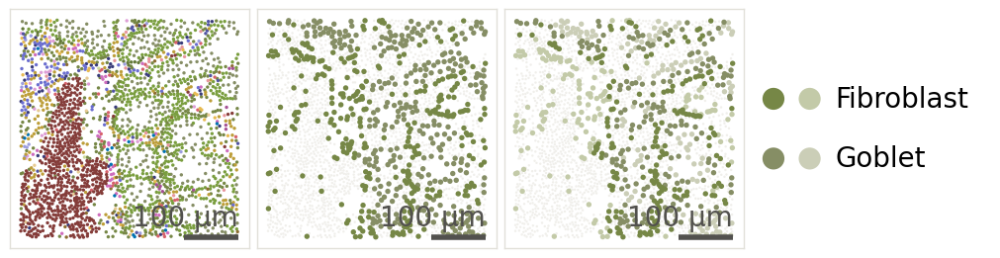

avoids_Goblet_to_Endothelial_with  ·  Control_Colon_02_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.049       0.203 0.523    -0.045       0.767           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_stage\avoids_Goblet_to_Endothelial_with.pdf


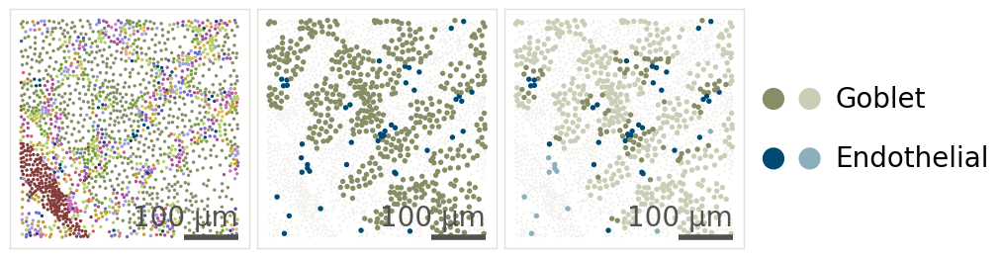

avoids_Goblet_to_Endothelial_without  ·  GVHD_22_FOV_3
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.005       0.071 0.292    -0.012       0.815           0.465
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_stage\avoids_Goblet_to_Endothelial_without.pdf


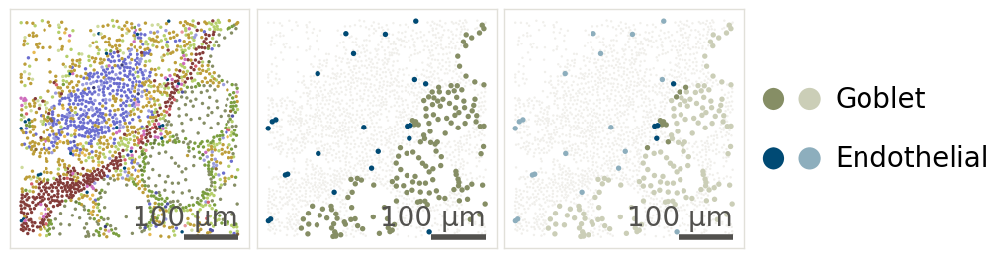

avoids_Goblet_to_CD4T_with  ·  Control_Colon_04_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.022        0.17  0.29    -0.054       0.499           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_stage\avoids_Goblet_to_CD4T_with.pdf


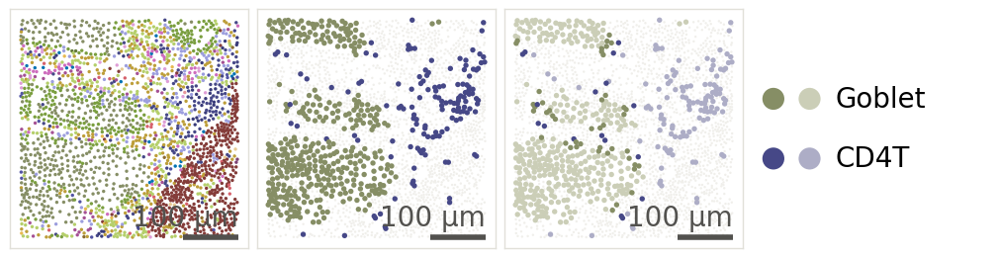

avoids_Goblet_to_CD4T_without  ·  GVHD_45_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.002       0.028  0.12    -0.018       0.785           0.471
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_Pathological_stage\avoids_Goblet_to_CD4T_without.pdf


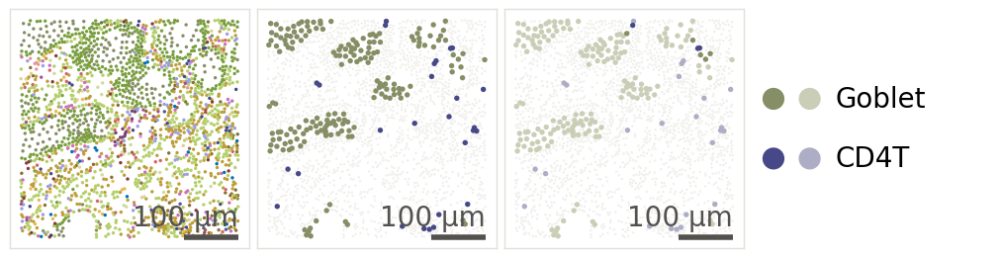

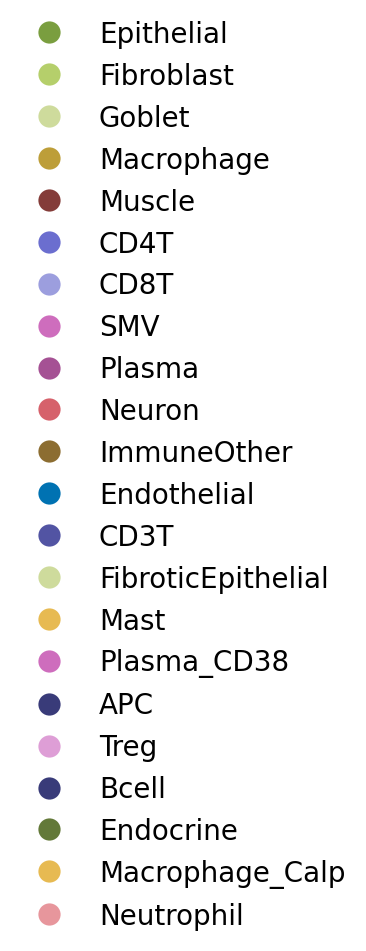

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,avoids,Fibroblast -> Goblet,2,True,GVHD_21_FOV_2,327
1,avoids,Fibroblast -> Goblet,0,False,GVHD_50_FOV_1,301
2,avoids,Goblet -> Endothelial,Control,True,Control_Colon_02_FOV_2,44
3,avoids,Goblet -> Endothelial,0,False,GVHD_22_FOV_3,23
4,avoids,Goblet -> CD4T,Control,True,Control_Colon_04_FOV_1,138
5,avoids,Goblet -> CD4T,1,False,GVHD_45_FOV_2,27


In [7]:
rule_examples("Colon", "Pathological stage")

### Colon · GI stage

avoids_Goblet_to_Fibroblast_with  ·  GVHD_41_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.039       0.335  0.38    -0.063       0.179           0.006
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_GI_stage\avoids_Goblet_to_Fibroblast_with.pdf


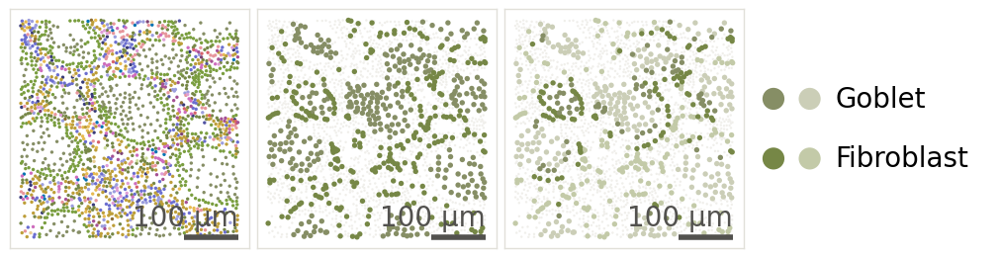

avoids_Goblet_to_Fibroblast_without  ·  GVHD_37_FOV_2
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_GI_stage\avoids_Goblet_to_Fibroblast_without.pdf


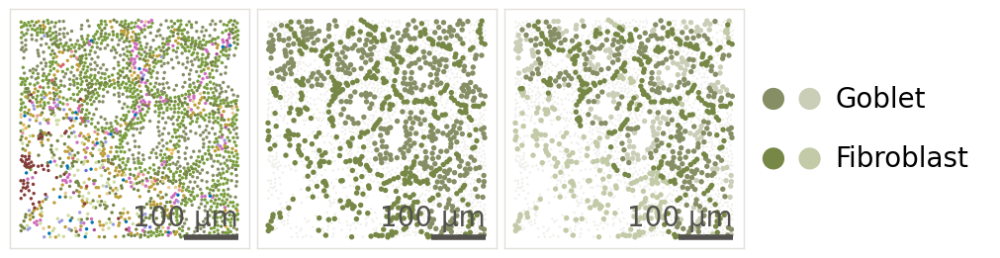

avoids_Goblet_to_CD8T_with  ·  Control_Colon_04_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.053       0.405 0.642    -0.029        0.62           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_GI_stage\avoids_Goblet_to_CD8T_with.pdf


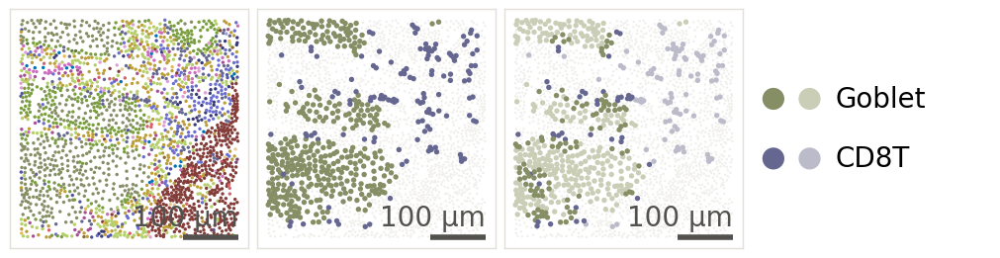

avoids_Goblet_to_CD8T_without  ·  GVHD_37_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.013       0.121  0.36    -0.022       0.755           0.602
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_GI_stage\avoids_Goblet_to_CD8T_without.pdf


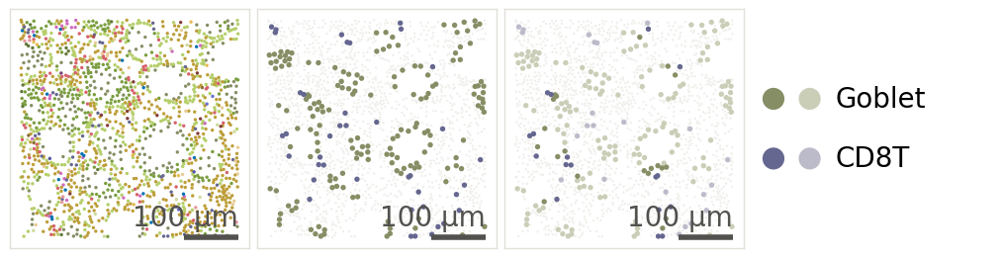

avoids_Goblet_to_Endothelial_with  ·  Control_Colon_02_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.049       0.203 0.523    -0.045       0.767           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_GI_stage\avoids_Goblet_to_Endothelial_with.pdf


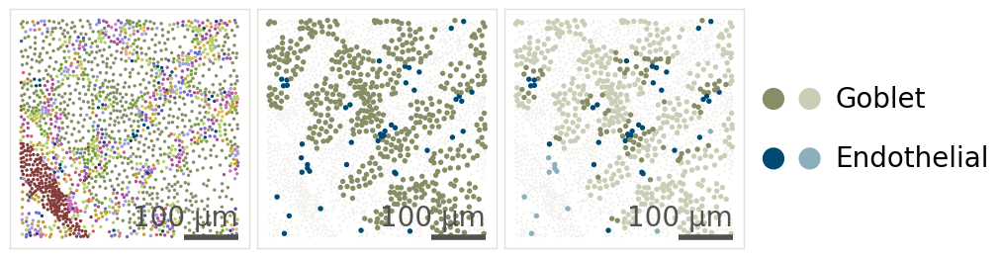

avoids_Goblet_to_Endothelial_without  ·  GVHD_21_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.004       0.045 0.185    -0.017       0.795           0.085
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Colon_GI_stage\avoids_Goblet_to_Endothelial_without.pdf


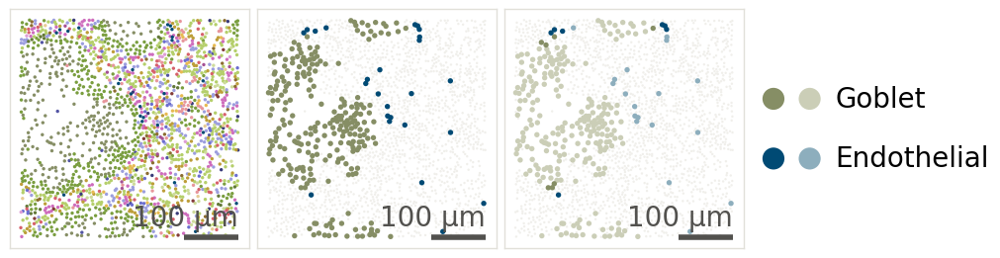

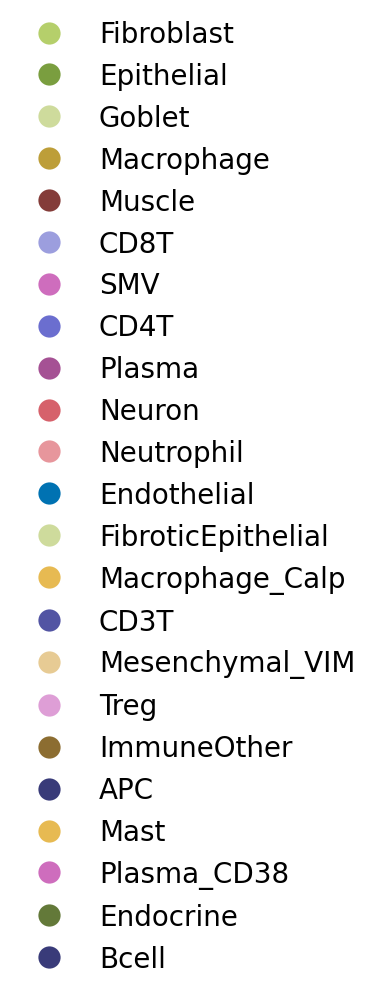

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,avoids,Goblet -> Fibroblast,2,True,GVHD_41_FOV_4,278
1,avoids,Goblet -> Fibroblast,3,False,GVHD_37_FOV_2,376
2,avoids,Goblet -> CD8T,Control,True,Control_Colon_04_FOV_1,135
3,avoids,Goblet -> CD8T,3,False,GVHD_37_FOV_4,40
4,avoids,Goblet -> Endothelial,Control,True,Control_Colon_02_FOV_2,44
5,avoids,Goblet -> Endothelial,1,False,GVHD_21_FOV_4,25


In [8]:
rule_examples("Colon", "GI stage")

### Colon · Days after Transplant grouped

### Duodenum · Pathological stage

attracts_Plasma_to_Plasma_CD38_with  ·  GVHD_26_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.038        0.94  1.38      0.01       5.296           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Pathological_stage\attracts_Plasma_to_Plasma_CD38_with.pdf


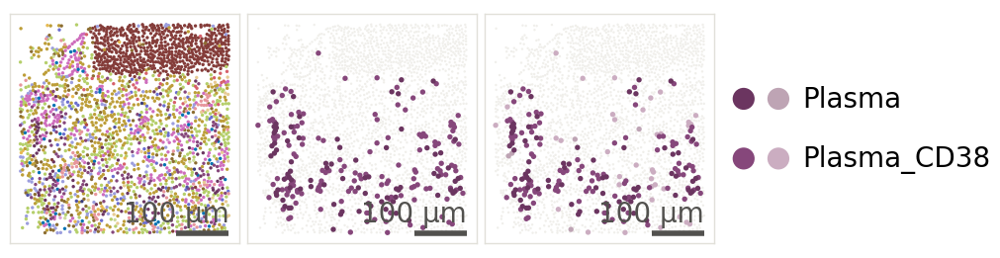

attracts_Plasma_to_Plasma_CD38_without  ·  Control_02_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.061       0.775 1.443     0.019       2.056             0.5
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Pathological_stage\attracts_Plasma_to_Plasma_CD38_without.pdf


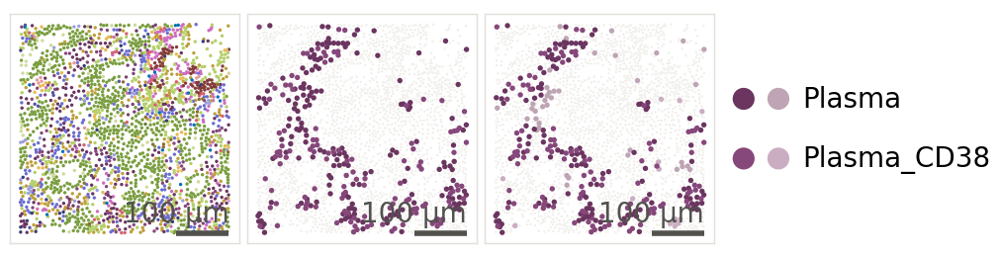

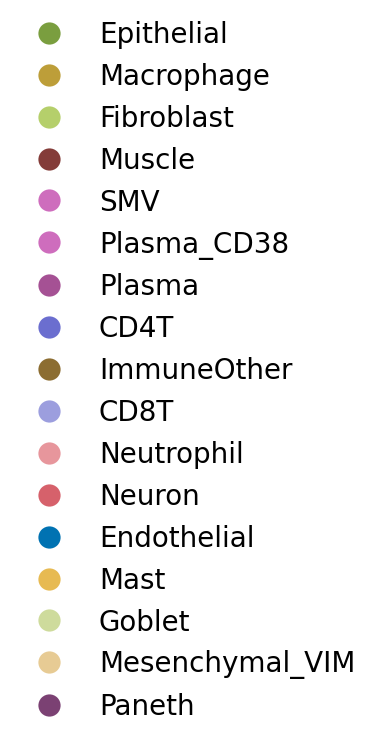

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Plasma -> Plasma_CD38,3,True,GVHD_26_FOV_4,83
1,attracts,Plasma -> Plasma_CD38,Control,False,Control_02_FOV_4,125


In [9]:
rule_examples("Duodenum", "Pathological stage")

### Duodenum · Cortico Response

attracts_SMV_to_Fibroblast_with  ·  GVHD_30_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.106       0.947 1.274     0.023       4.856           0.004
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Cortico_Response\attracts_SMV_to_Fibroblast_with.pdf


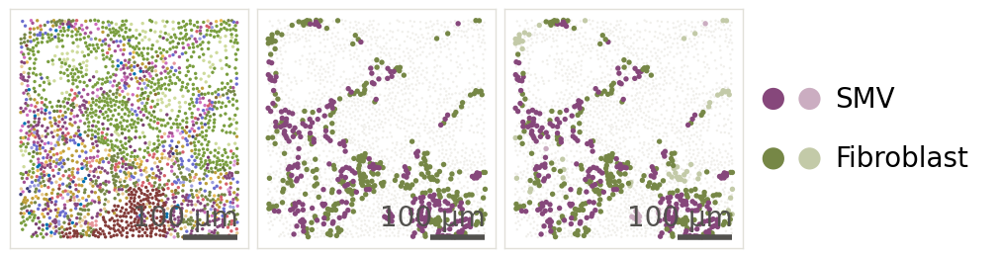

attracts_SMV_to_Fibroblast_without  ·  GVHD_06_FOV_5
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Cortico_Response\attracts_SMV_to_Fibroblast_without.pdf


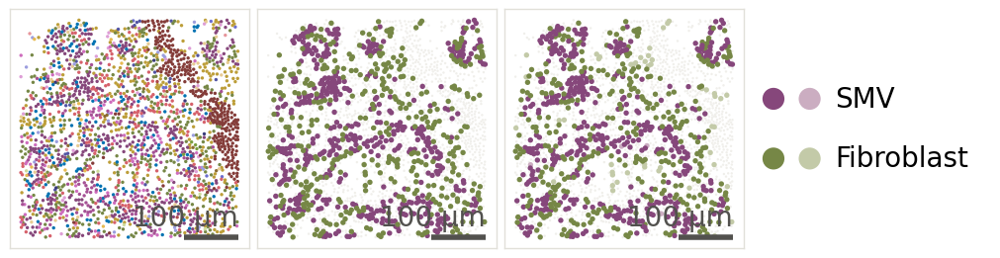

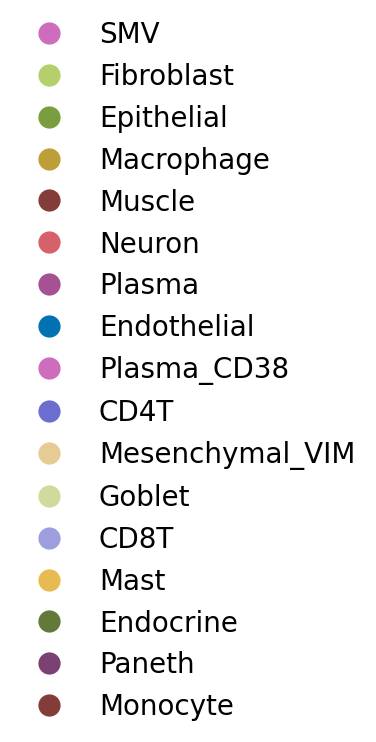

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,SMV -> Fibroblast,Responder,True,GVHD_30_FOV_2,246
1,attracts,SMV -> Fibroblast,Non-responder,False,GVHD_06_FOV_5,391


In [10]:
rule_examples("Duodenum", "Cortico Response")

### Duodenum · Days after Transplant grouped

attracts_Plasma_CD38_to_Fibroblast_with  ·  GVHD_27_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.072       0.962 1.308     0.017        7.05           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Days_after_Transplant_grouped\attracts_Plasma_CD38_to_Fibroblast_with.pdf


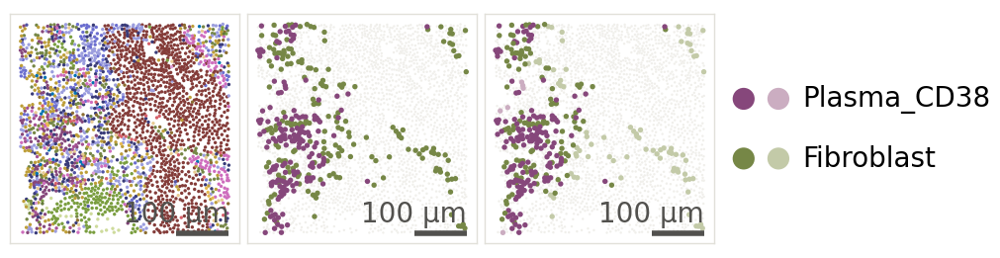

attracts_Plasma_CD38_to_Fibroblast_without  ·  Control_01_FOV_4
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Days_after_Transplant_grouped\attracts_Plasma_CD38_to_Fibroblast_without.pdf


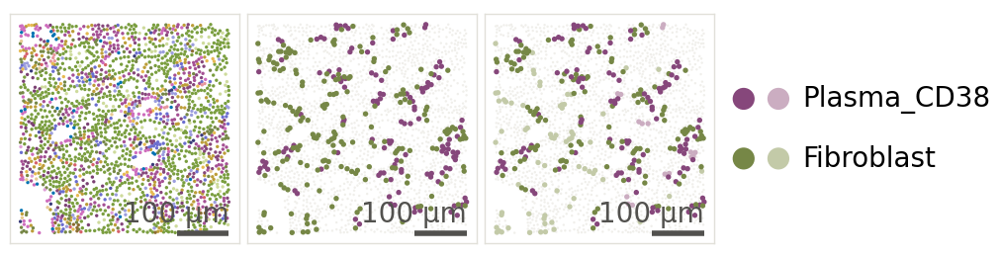

attracts_Plasma_to_Fibroblast_with  ·  GVHD_58_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.108       0.875 1.263     0.022       2.456           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Days_after_Transplant_grouped\attracts_Plasma_to_Fibroblast_with.pdf


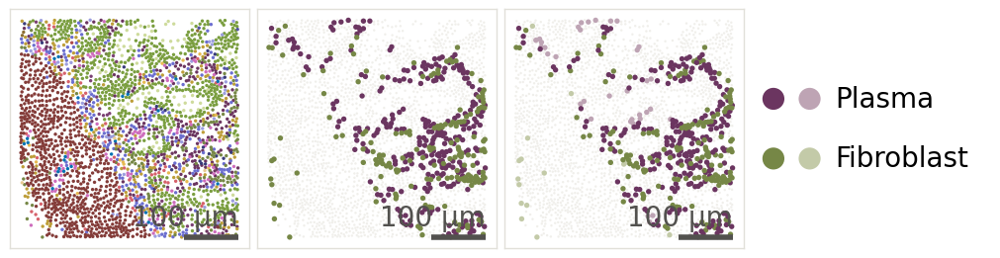

attracts_Plasma_to_Fibroblast_without  ·  Control_09_FOV_1
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV\Duodenum_Days_after_Transplant_grouped\attracts_Plasma_to_Fibroblast_without.pdf


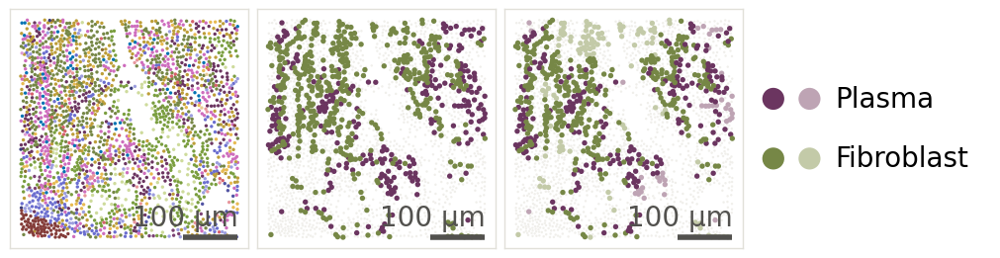

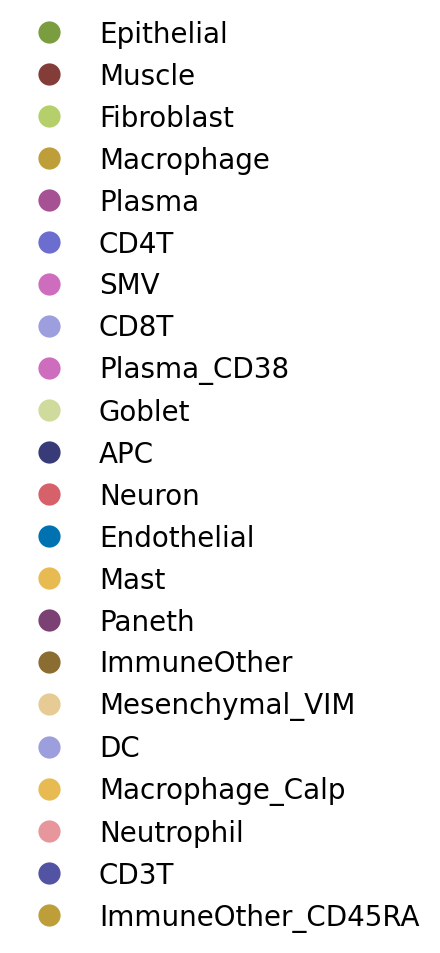

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Plasma_CD38 -> Fibroblast,>100,True,GVHD_27_FOV_2,160
1,attracts,Plasma_CD38 -> Fibroblast,Control,False,Control_01_FOV_4,127
2,attracts,Plasma -> Fibroblast,30-100,True,GVHD_58_FOV_3,169
3,attracts,Plasma -> Fibroblast,Control,False,Control_09_FOV_1,252


In [11]:
rule_examples("Duodenum", "Days after Transplant grouped")